# Week 4: Map your set

To start, save a copy to your Drive (File, then Save a copy in Drive), then run the cells in order. It runs on Colab's free CPU runtime. The outputs below are from the 56 museum chairs in the week 4 slides.

## 1. Setup

This loads CLIP, which takes about a minute.

In [1]:
import glob, io, os, sys, zipfile
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install umap-learn
import numpy as np, torch, umap
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from PIL import Image, ImageOps
from transformers import CLIPModel, CLIPProcessor

dev = "cuda" if torch.cuda.is_available() else "cpu"
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(dev).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
print("ready")

ready


## 2. Your images

With USE_EXAMPLE = True, it downloads the museum chairs. To use your own images, set it to False and run the cell again, and it will ask for a zip of your 20 to 40 designs.

In [2]:
USE_EXAMPLE = True  # True: the 56 museum chairs. False: upload a zip of your own images.
TRAIN_DIR = "train"

def unzip_upload(folder):
    """Ask for a zip of images (or several image files) and put them in `folder`."""
    from google.colab import files
    os.makedirs(folder, exist_ok=True)
    for name, data in files.upload().items():
        if name.lower().endswith(".zip"):
            zipfile.ZipFile(io.BytesIO(data)).extractall(folder)
        else:
            open(os.path.join(folder, name), "wb").write(data)

if USE_EXAMPLE:
    import csv, requests
    base = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/museum-chairs/"
    names = [r["file"] for r in csv.DictReader(io.StringIO(requests.get(base + "credits.csv", timeout=60).text))]
    os.makedirs(TRAIN_DIR, exist_ok=True)
    for f in names:
        open(os.path.join(TRAIN_DIR, f), "wb").write(requests.get(f"{base}train/{f}", timeout=60).content)
    print("downloaded the example:", len(names), "chairs")
else:
    print("Pick a zip of your images:")
    unzip_upload(TRAIN_DIR)

downloaded the example: 56 chairs


## 3. Embed your images

This turns each image into 512 numbers with CLIP.

In [3]:
EXT = (".jpg", ".jpeg", ".png", ".webp")
def images_in(folder):
    return sorted(p for p in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
                  if p.lower().endswith(EXT) and "__MACOSX" not in p)

def embed(paths):
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), 16):
            ims = [Image.open(p).convert("RGB") for p in paths[i:i + 16]]
            e = model.get_image_features(**proc(images=ims, return_tensors="pt").to(dev))
            if not torch.is_tensor(e):  # newer versions of transformers return an object
                e = e.image_embeds if getattr(e, "image_embeds", None) is not None else e.pooler_output
                if e.shape[-1] != model.config.projection_dim:
                    e = model.visual_projection(e)
            out.append(torch.nn.functional.normalize(e, dim=-1).cpu().numpy())
    return np.concatenate(out)

train = images_in(TRAIN_DIR)
E = embed(train)
print(len(train), "images")

56 images


## 4. Map

Images with similar numbers are placed close together. If two groups are far apart, you can use them as the two ends of a slider in week 5.

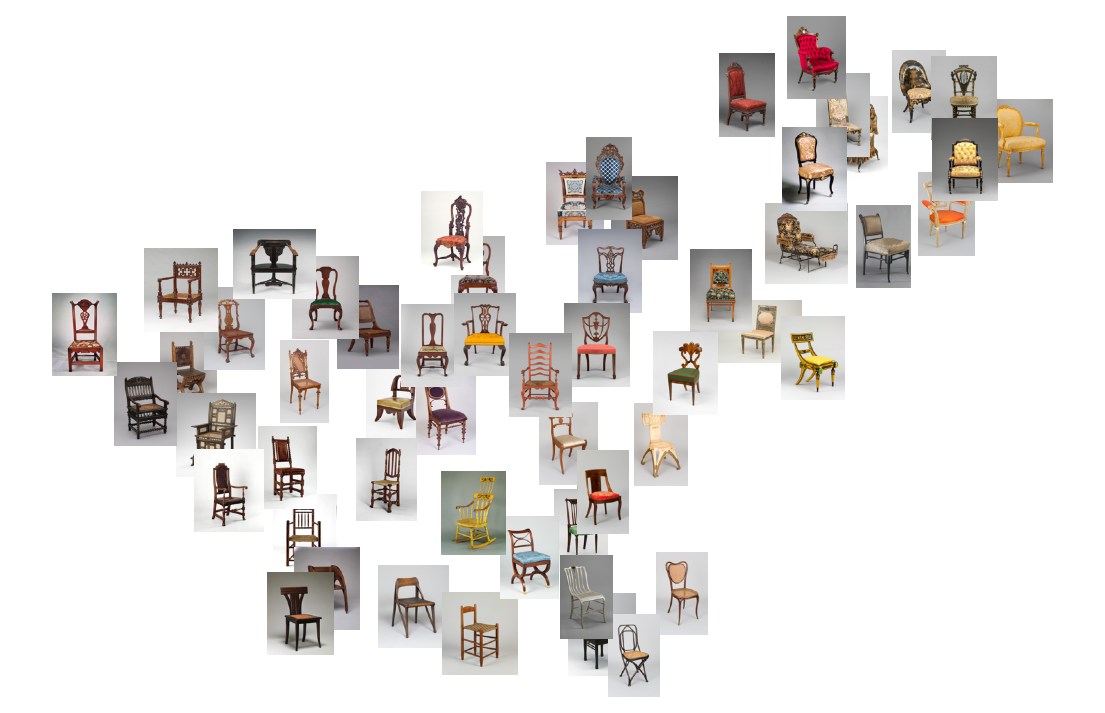

In [4]:
reducer = umap.UMAP(n_neighbors=min(15, len(train) - 1), min_dist=0.3, metric="cosine", random_state=0)
xy = reducer.fit_transform(E)

def thumb(ax, path, x, y, size=0.5):
    im = Image.open(path).convert("RGB")
    im.thumbnail((120, 120))
    ax.add_artist(AnnotationBbox(OffsetImage(np.asarray(im), zoom=size), (x, y), frameon=False))

fig, ax = plt.subplots(figsize=(14, 9))
for (x, y), p in zip(xy, train):
    thumb(ax, p, x, y)
pad = (xy.max(0) - xy.min(0)) * 0.08
ax.set_xlim(xy[:, 0].min() - pad[0], xy[:, 0].max() + pad[0])
ax.set_ylim(xy[:, 1].min() - pad[1], xy[:, 1].max() + pad[1])
ax.axis("off")
plt.savefig("map.jpg", dpi=120, bbox_inches="tight")
plt.show()

## 5. Search with words

You can change WORDS to your own words and run the cell again, and it will show the four closest images for each word.

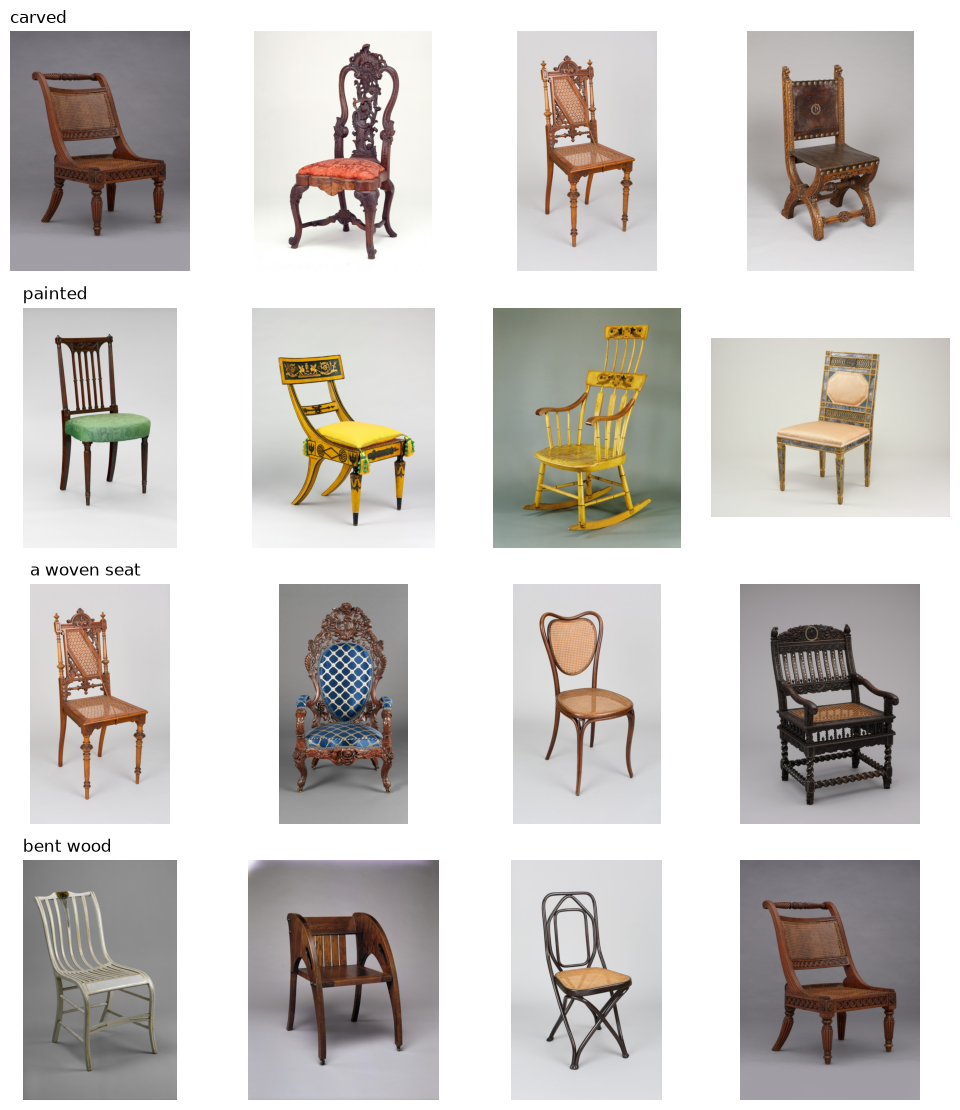

In [5]:
WORDS = ["carved", "painted", "a woven seat", "bent wood"]  # try your own words

with torch.no_grad():
    t = model.get_text_features(**proc(text=[f"a photo of a chair with {w}" if w.startswith("a ") else f"a photo of a {w} chair" for w in WORDS], return_tensors="pt", padding=True).to(dev))
    if not torch.is_tensor(t):
        t = t.text_embeds if getattr(t, "text_embeds", None) is not None else t.pooler_output
        if t.shape[-1] != model.config.projection_dim:
            t = model.text_projection(t)
    T = torch.nn.functional.normalize(t, dim=-1).cpu().numpy()
S = T @ E.T
fig, axes = plt.subplots(len(WORDS), 4, figsize=(10, 2.8 * len(WORDS)), squeeze=False)
for i, w in enumerate(WORDS):
    for k, j in enumerate(np.argsort(-S[i])[:4]):
        axes[i, k].imshow(Image.open(train[j]).convert("RGB"))
        axes[i, k].axis("off")
    axes[i, 0].set_title(w, loc="left", fontsize=12)
plt.tight_layout()
plt.savefig("search.jpg", dpi=110)
plt.show()

## 6. Compare two sets of captions

Write your own caption for each design in a file called captions.csv, with two columns, file and caption (the name of each image file and your words for it), and upload it when the cell asks. The cell also writes captions automatically with BLIP, an image captioning model, which takes a few minutes. For each phrase in WORDS, it finds the four designs whose captions are closest to the phrase, once with the automatic captions and once with yours, and prints how many of the four are the same. With USE_EXAMPLE = True, the second set is the title and materials from each chair's museum record. For the hand-in, download captions-compare.jpg and map.jpg from the Files panel on the left, and write a few sentences on which captions found the designs you meant, and what the other set missed.

aic-100712.jpg
  automatic: a close up of a chair with a floral seat cushion
  yours:     Side Chair, Walnut and 18th-century replacement upholstery
aic-102774.jpg
  automatic: there is a chair with a foot rest and a foot rest on it
  yours:     Chair, Iron, walnut, cane, and upholstery
aic-105287.jpg
  automatic: there is a wooden chair with a leather seat on a white background
  yours:     Side Chair, Bog oak and leather


carved: 0 of the top 4 are the same
painted: 1 of the top 4 are the same
a woven seat: 0 of the top 4 are the same
bent wood: 1 of the top 4 are the same


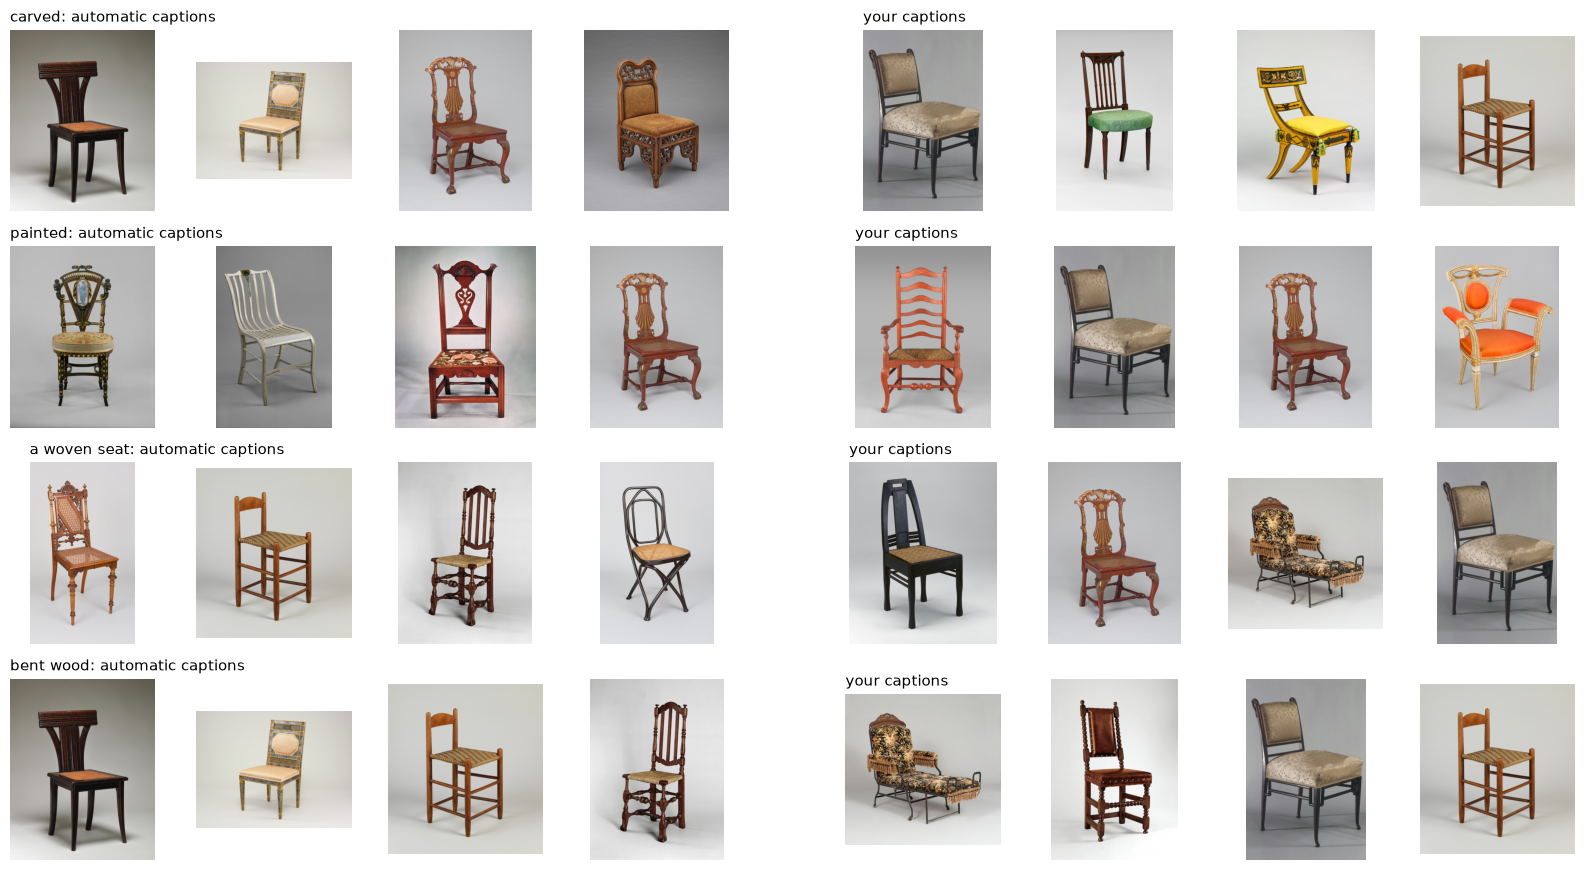

In [6]:
# Your captions: a file captions.csv with two columns, file and caption, one row for each image.
if USE_EXAMPLE:  # the second set for the example: each chair's title and materials from its museum record
    if not os.path.exists("captions.csv"):
        open("captions.csv", "w").write(requests.get(base + "captions-museum.csv", timeout=60).text)
else:
    print("Pick your captions.csv:")
    unzip_upload(".")

import csv
from transformers import BlipForConditionalGeneration, BlipProcessor
bproc = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-large")
blip = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-large").to(dev).eval()
files = [os.path.basename(p) for p in train]
auto = []
with torch.no_grad():
    for p in train:
        out = blip.generate(**bproc(images=Image.open(p).convert("RGB"), return_tensors="pt").to(dev), max_new_tokens=30)
        auto.append(bproc.decode(out[0], skip_special_tokens=True))
yours = {r["file"]: r["caption"] for r in csv.DictReader(open("captions.csv"))}
yours = [yours.get(f, "") for f in files]
for f, a, y in list(zip(files, auto, yours))[:3]:
    print(f"{f}\n  automatic: {a}\n  yours:     {y}")

def text_embed(texts):
    with torch.no_grad():
        t = model.get_text_features(**proc(text=texts, return_tensors="pt", padding=True, truncation=True).to(dev))
        if not torch.is_tensor(t):
            t = t.text_embeds if getattr(t, "text_embeds", None) is not None else t.pooler_output
            if t.shape[-1] != model.config.projection_dim:
                t = model.text_projection(t)
    return torch.nn.functional.normalize(t, dim=-1).cpu().numpy()

A, Y = text_embed(auto), text_embed(yours)
Q = text_embed([f"a chair with {w}" if w.startswith("a ") else f"a {w} chair" for w in WORDS])
fig, axes = plt.subplots(len(WORDS), 9, figsize=(16, 2.2 * len(WORDS)), squeeze=False,
                         gridspec_kw={"width_ratios": [1, 1, 1, 1, 0.25, 1, 1, 1, 1]})
for i, w in enumerate(WORDS):
    top_a, top_y = np.argsort(-(Q[i] @ A.T))[:4], np.argsort(-(Q[i] @ Y.T))[:4]
    for k, j in enumerate(top_a):
        axes[i, k].imshow(Image.open(train[j]).convert("RGB"))
    for k, j in enumerate(top_y):
        axes[i, 5 + k].imshow(Image.open(train[j]).convert("RGB"))
    for ax in axes[i]:
        ax.axis("off")
    axes[i, 0].set_title(f"{w}: automatic captions", loc="left", fontsize=11)
    axes[i, 5].set_title("your captions", loc="left", fontsize=11)
    print(f"{w}: {len(set(top_a) & set(top_y))} of the top 4 are the same")
plt.tight_layout()
plt.savefig("captions-compare.jpg", dpi=100)
plt.show()